In [1]:
import os
import sys
import time

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator

sys.path.insert(0, '../../..')
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs

TARGET_MOVEMENT = 'Place'

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [ ]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [4]:
cache_path = Configs.all_sensors_dtw_distance_matrix(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"DTW distance matrix for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")   

dtw_matrix = joblib.load(cache_path)

In [5]:
# Load Times for benchmarking
times_path = Configs.ALL_SENSORS_DTW_CALCULATION_TIMES_CACHE
if not os.path.exists(times_path):
    raise FileNotFoundError(f"DTW calculation times not found at {times_path}. Please run the feature extraction notebook first.")

times = joblib.load(times_path)

In [6]:
group_array = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw']
sample_size = None

# Usar o TimeSeriesScalerMeanVariance para normalizar as séries temporais,
# mas sem escalar para zero média e unidade de variância (useScaler=False)
X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series:   0%|          | 0/380 [00:00<?, ?it/s]

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 3854.85it/s]


Shape of first series: (290, 9)
Shape of formatted series: (380, 290, 9)


## DBSCAN 
O DNSCAN não sabe o que é o DTW, somente distâncias numéricas. Então, para fazer o DBSCAN tenho de lhe passar uma matriz de distâncias já calculadas.

Calculating distances to the 4th neighbor...
Detecting the elbow point (ideal EPS)...
The mathematical value of EPS (Elbow) is: 808.8613572980282


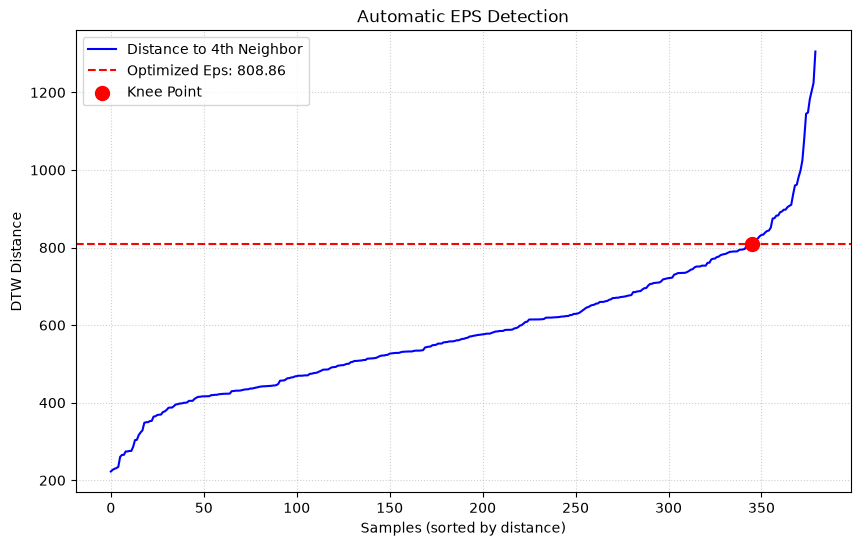

In [7]:
# --- PART 2 (THE MISSING LINKS): Calculate Distances to k-Neighbors ---
# Set k equal to the min_samples you will use in DBSCAN (e.g., 4)
k = 4 

print(f"Calculating distances to the {k}th neighbor...")
# We use 'precomputed' because we already have the DTW matrix ready
nbrs = NearestNeighbors(n_neighbors=k, metric='precomputed')
nbrs.fit(dtw_matrix)

# distances: distances to the k nearest neighbors
# indices: who these neighbors are (not needed now)
distances, indices = nbrs.kneighbors(dtw_matrix)

# Take the distance to the k-th neighbor (column k-1) and sort
k_distances = np.sort(distances[:, k-1])


# --- FIND ELBOW AUTOMATICALLY (Kneedle) ---
print("Detecting the elbow point (ideal EPS)...")

x = range(len(k_distances))

# Vital configuration for Kneedle to work well on this type of plot:
# curve='convex' (because the curve's belly is downward/outward)
# direction='increasing' (because the values are increasing)
kneedle = KneeLocator(x, k_distances, curve='convex', direction='increasing')

optimal_eps = kneedle.elbow_y
print(f"The mathematical value of EPS (Elbow) is: {optimal_eps}")


# --- PLOT ---
plt.figure(figsize=(10, 6))
plt.plot(x, k_distances, label=f'Distance to {k}th Neighbor', color='blue', linewidth=1.5)

# Suggested EPS line
if optimal_eps is not None:
    plt.axhline(y=optimal_eps, color='r', linestyle='--', label=f'Optimized Eps: {optimal_eps:.2f}')
    plt.scatter([kneedle.elbow], [optimal_eps], color='red', s=100, zorder=5, label='Knee Point')
else:
    print("Warning: The algorithm could not find a clear elbow. Please check the plot.")

plt.title(f'Automatic EPS Detection')
plt.xlabel('Samples (sorted by distance)')
plt.ylabel('DTW Distance')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Grid Search

In [ ]:
# --- 1. PREPARAÇÃO DIRETA ---
# Filtrar o DataFrame bruto para obter os metadados do movimento atual
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)

# A sua nova base de cálculo: Repetições ÚNICAS
total_trials_unique = df_filtered.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)

# --- 2. PARÂMETROS DINÂMICOS ---
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100

print(f"\n--- Preparação DBSCAN (DTW Precomputed) ---")
print(f"Total de repetições únicas analisadas ({TARGET_MOVEMENT}): {total_trials}")
print(f"Taxa mínima confirmada de outliers no CSV: {percentagem_conhecida:.2f}%")

# Espaço de Busca (Grid)
min_samples_options = [3, 4, 5, 7, 10]

# ESTRATÉGIA HÍBRIDA PARA O EPSILON:
# Assumindo que você já rodou o Kneedle antes e guardou o valor na variável `optimal_eps`
# Vamos procurar 15% abaixo e 15% acima do valor do cotovelo para afinar a decisão
eps_min = optimal_eps * 0.85
eps_max = optimal_eps * 1.15
eps_options = np.linspace(eps_min, eps_max, 20)
eps_options = [round(e, 2) for e in eps_options]

results_log = []

for m_samp in min_samples_options:
    for eps_val in eps_options:
        
        # TREINO DO DBSCAN (metric='precomputed' para a matriz DTW)
        model = DBSCAN(eps=eps_val, min_samples=m_samp, metric='precomputed')
        
        # Fit predict direto na matriz DTW crua
        labels = model.fit_predict(dtw_matrix)
        
        # --- CÁLCULO DE MÉTRICAS (A SUA LÓGICA DE ÚNICOS) ---
        results_temp = results_temp_base.copy()
        results_temp['label'] = labels
        
        # Isolar quem foi classificado como lixo (-1)
        real_outliers_info = results_temp[results_temp['label'] == -1]

        # GARANTIR QUE OS IDENTIFICADOS SÃO ÚNICOS (Efeito de Mordiscada resolvido!)
        identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

        # Cruzar com o Gabarito (Ground Truth)
        matched = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

        # TP e FP baseados nas repetições únicas
        TP = len(matched)
        FP = len(identified_unique) - TP
        
        # Falhas (FN)
        missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
        FN = len(missing_outliers[missing_outliers['_merge'] == 'left_only'])
        
        recall = (TP / total_known_outliers) * 100 if total_known_outliers > 0 else 0
        precision = (TP / (TP + FP)) * 100 if (TP + FP) > 0 else 0
        
        if (precision + recall) > 0:
            f1_score = 2 * (precision * recall) / (precision + recall)
            f2_score = 5 * (precision * recall) / (4 * precision + recall) if (4 * precision + recall) > 0 else 0
        else:
            f1_score = 0
            f2_score = 0
            
        results_log.append({
            'min_samples': m_samp,
            'eps': eps_val,
            'Recall': recall,
            'Precision': precision,
            'F1-Score': f1_score,
            'F2-Score': f2_score,
            'TP': TP,
            'FP': FP,
            'FN': FN,
            'Percentagem Lixo': (len(identified_unique) / total_trials) * 100 
        })


--- Preparação DBSCAN (DTW Precomputed) ---
Total de repetições únicas analisadas (Place): 95
Taxa mínima confirmada de outliers no CSV: 14.74%

--- Iniciando Grid Search Dinâmico (DBSCAN + DTW) ---

TOP 5 CONFIGURAÇÕES (DBSCAN - DTW): Limite Lixo=19.7%
    min_samples     eps  Percentagem Lixo     Recall  Precision   F1-Score
4             3  738.62         15.789474  42.857143  40.000000  41.379310
3             3  725.85         17.894737  42.857143  35.294118  38.709677
2             3  713.08         18.947368  42.857143  33.333333  37.500000
24            4  738.62         18.947368  42.857143  33.333333  37.500000
73            7  853.56         18.947368  42.857143  33.333333  37.500000

🏆 VENCEDOR DO GRID SEARCH (DBSCAN - DTW):
Min Samples: 3.0
Epsilon (Eps): 738.62
F1-Score: 41.3793
F2-Score: 42.2535
True Positives: 6.0
False Positives: 9.0
False Negatives: 8.0
Recall: 42.86% (6/14)
Lixo Rejeitado Global: 15.79%


In [ ]:
# --- Seleção do Melhor Modelo ---
results_df = pd.DataFrame(results_log)

# Limitar o lixo: A percentagem conhecida + 5% de tolerância
limite_lixo = percentagem_conhecida + 5.0 
acceptable_models = results_df[results_df['Percentagem Lixo'] <= limite_lixo]

if acceptable_models.empty:
    print(f"Aviso: Nenhum modelo conseguiu ter menos de {limite_lixo:.1f}% de lixo. A usar todos.")
    acceptable_models = results_df

# Ordenar pelo Recall e F2-Score
best_results = acceptable_models.sort_values(by=['Recall', 'F2-Score'], ascending=False)

print(f"\nTOP 5 CONFIGURAÇÕES (DBSCAN - DTW): Limite Lixo={limite_lixo:.1f}%")
print(best_results[['min_samples', 'eps', 'Percentagem Lixo', 'Recall', 'Precision', 'F1-Score']].head(5))

best_params = best_results.iloc[0]

print(f"\n🏆 VENCEDOR DO GRID SEARCH (DBSCAN - DTW):")
print(f"Min Samples: {best_params['min_samples']}")
print(f"Epsilon (Eps): {best_params['eps']}")
print(f"F1-Score: {best_params['F1-Score']:.4f}")
print(f"F2-Score: {best_params['F2-Score']:.4f}")
print(f"True Positives: {best_params['TP']}")
print(f"False Positives: {best_params['FP']}")
print(f"False Negatives: {best_params['FN']}")
print(f"Recall: {best_params['Recall']:.2f}% ({int(best_params['TP'])}/{total_known_outliers})")
print(f"Lixo Rejeitado Global: {best_params['Percentagem Lixo']:.2f}%")

## Treinar Modelo Final

In [9]:
best_eps = best_params['eps']
best_min_samples = int(best_params['min_samples']) # Cast para int ou o DBSCAN reclama

start_time = time.perf_counter()

db = DBSCAN(eps=best_eps,min_samples=best_min_samples, metric='precomputed')
labels = db.fit_predict(dtw_matrix)

end_time = time.perf_counter()
elapsed_time = end_time - start_time
elapsed_time_with_dtw = elapsed_time + times[TARGET_MOVEMENT]

outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)
X_movement_clean = np.delete(X_movement, outlier_indices, axis=0) # shape (n_samples - n_outliers, T, n_features)
X_movement_outliers = X_movement[outlier_indices] # shape (n_outliers, T, n_features)

print(labels)
print(f"Total Analisado: {len(dtw_matrix)}")
print(f"Outliers Detetados: {n_outliers}")
print(f"Percentagem de Lixo: {n_outliers/len(dtw_matrix)*100:.2f}%")
print(f"Percentagem de Retenção: {(len(dtw_matrix) - n_outliers)/len(dtw_matrix)*100:.2f}%")
print(f"Tempo de Execução do DBSCAN (sem DTW): {elapsed_time:.2f} segundos")
print(f"Tempo Total (DTW + DBSCAN): {elapsed_time_with_dtw:.2f} segundos")

[-1  0  1  0  1  0  1  0  1  0  1  0  1  0  1  0  1  0  1  0  2  3 -1  3
  2  3  2  3  2  3  2  3  2  3  2  3  2  3  2  3  4  5  4  5  6  5  6  5
  6  5  6 -1  6  5  6  5  6 -1 -1 -1  7  8  7  8  7  8  7  8  7  8  7  8
  7  8  7  8  7  8  7  8 -1 -1 -1  9 -1  9 10  9 10  9 10 -1 10  9 10  9
 -1  9 10  9  4  0 -1  5  4  5  4  5  4  5  4  5  4  5  4  5  4  5  4  5
  2 11  2 11  2 11  2 11  2 11  2 11  2 11  2 11  2 11  2 11 -1  5  4 12
  4 12  4 12  1 12  4 12  4 12  4 12  4 12  4 12 13 14 13 14 13 14 13 14
 13 14 13 14 13 14 13 14 13 14 13 14 15 16 15 16 15 16 15 16 15 16 15 16
 15 16 15 16 15 16 15 16 -1 17 18 17 18 17 18 17 18 17 18 17 18 17 18 17
 18 17 18 17 15 16 15 -1 15 16 15 16 15 16 15 16 15 16 15 16 15 16 15 16
 20 19 20 19 20 19 20 19 20 19 -1 19 20 19 20 19 20 19 20 19 21 22 21 22
 21 22 21 22 21 22 21 22 21 22 21 22 21 22 21 22 15 16 15 16 15 16 15 16
 15 16 15 16 15 16 15 16 15 16 15 16 -1 24 23 24 23 24 23 24 23 24 23 24
 23 24 23 24 23 24 23 24 15  5 15  5 15  5 15  5 15

In [10]:
# 1. Recriar a lista de identidades NA MESMA ORDEM que o X_movement foi gerado
# Nota: É crucial usar o mesmo filtro e ordem que usou no 'normalize_series'
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT]

# Agrupar pelas chaves únicas para obter a lista de movimentos
# sort=False preserva a ordem de aparição (geralmente mais seguro se não ordenou explicitamente antes)
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()

# Criar um DataFrame auxiliar apenas com os Metadados (Índice 0 = 1º Movimento, Índice 1 = 2º Movimento...)
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# 2. Merge dos Indíces do LOF com os Metadados
if len(metadata_df) != len(X_movement):
    print("⚠️ AVISO CRÍTICO: O número de movimentos não bate certo! Verifique a filtragem.")
else:
    # Filtrar o DataFrame de Metadados usando os índices do LOF
    real_outliers_info = metadata_df.iloc[outlier_indices]
    
    print("Quem são os outliers reais?")
    print(real_outliers_info)

Quem são os outliers reais?
     sub  repID  movID movLabel
0      6      1      2    Place
22    11      1      6    Place
51    18      3      8    Place
57    18      5      4    Place
58    18      5      6    Place
59    18      5      8    Place
80     5      1      2    Place
81     5      1      4    Place
82     5      1      6    Place
84     5      2      2    Place
91     5      3      8    Place
96     5      5      2    Place
102    7      1      6    Place
140   16      1      2    Place
200   15      1      2    Place
223    3      1      8    Place
250   14      3      6    Place
300    4      1      2    Place
376    8      5      2    Place
377    8      5      4    Place


In [11]:
# 1. Garantir que os outliers identificados também são únicos por sub e repID
# Assim, se um algoritmo deitar fora 3 'movID' da mesma 'repID', conta apenas como 1 True Positive
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# 2. Cruzamento (Match)
matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

# 3. Encontrar os que falharam (Missing / False Negatives)
missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']


# --- CÁLCULO DAS MÉTRICAS ---
metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- MATRIZ DE CONFUSÃO (Baseada em sub+repID) ---
True Positives (Identificados e no CSV) : 6
False Positives (Identificados, não CSV): 9
False Negatives (No CSV, não identificados): 8
True Negatives (Normais, mantidos normais): 72
--------------------------------------------------
Missing outliers (Escaparam ao algoritmo):
    sub  repID
0     2      2
5     8      1
6     9      1
8    12      1
9    13      1
11   16      5
12   18      2
13   19      2

Precision (Precisão) (Falsos Alarmes): 6/15 (40.00%)
Recall (Taxa de Acerto): 6/14 (42.86%)
F1-Score: 41.38%
F2-Score: 42.25%


A desenhar trajetórias do Ombro...


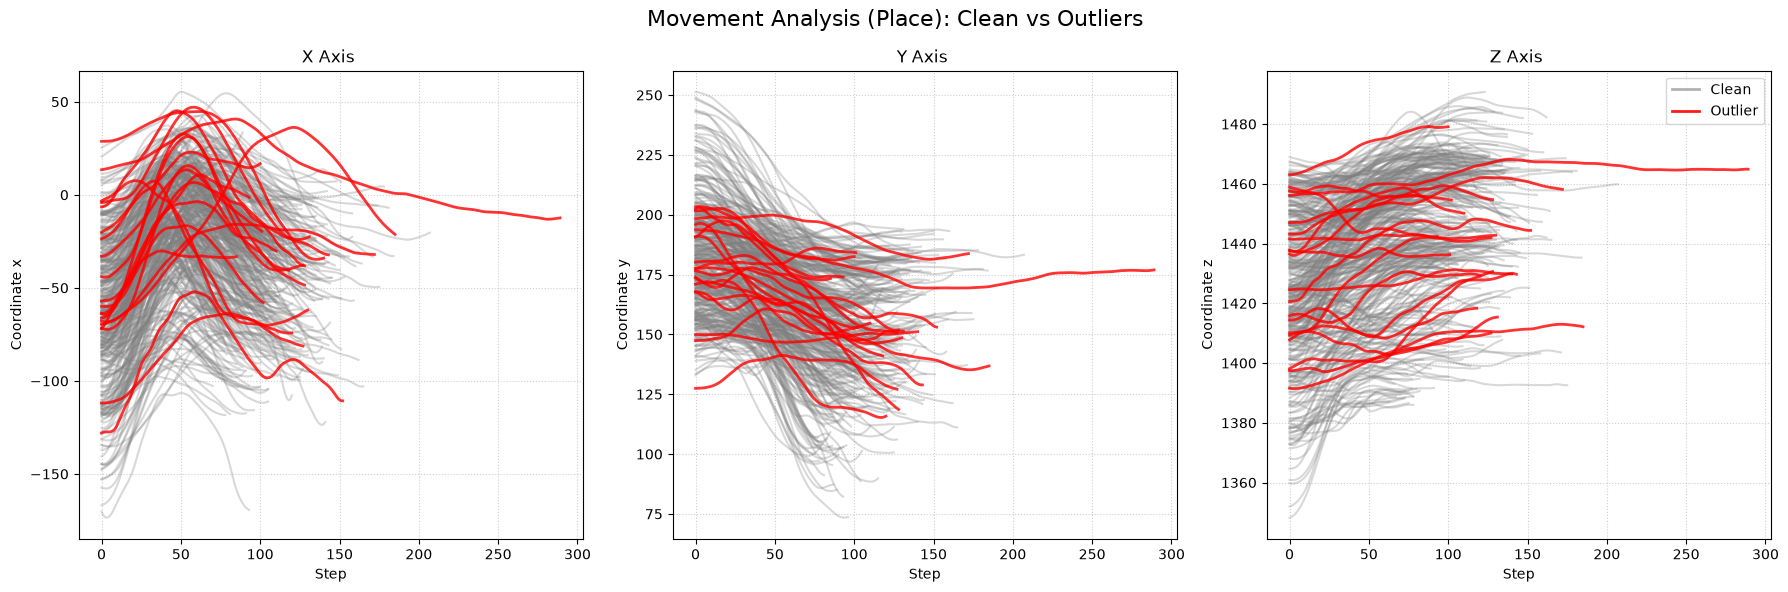

A desenhar trajetórias do Cotovelo...


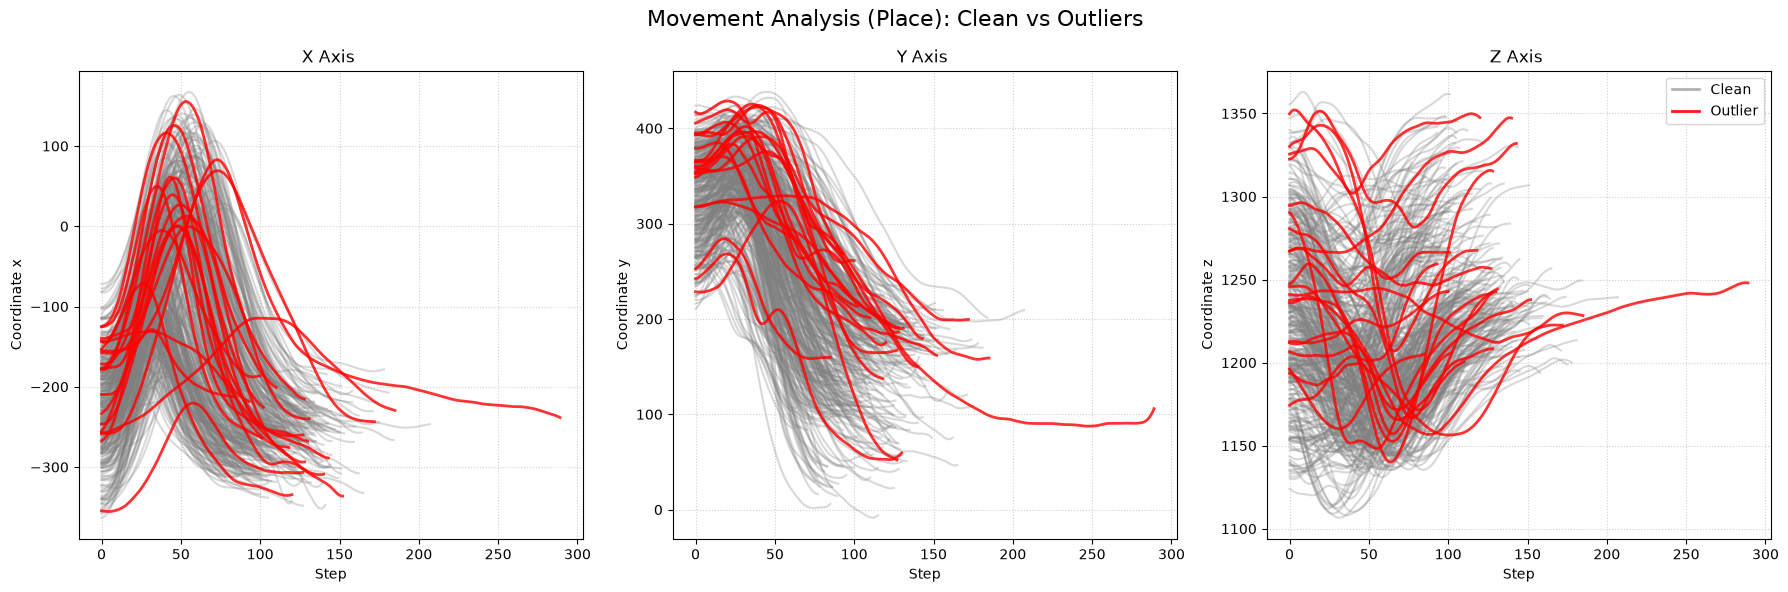

A desenhar trajetórias do Pulso...


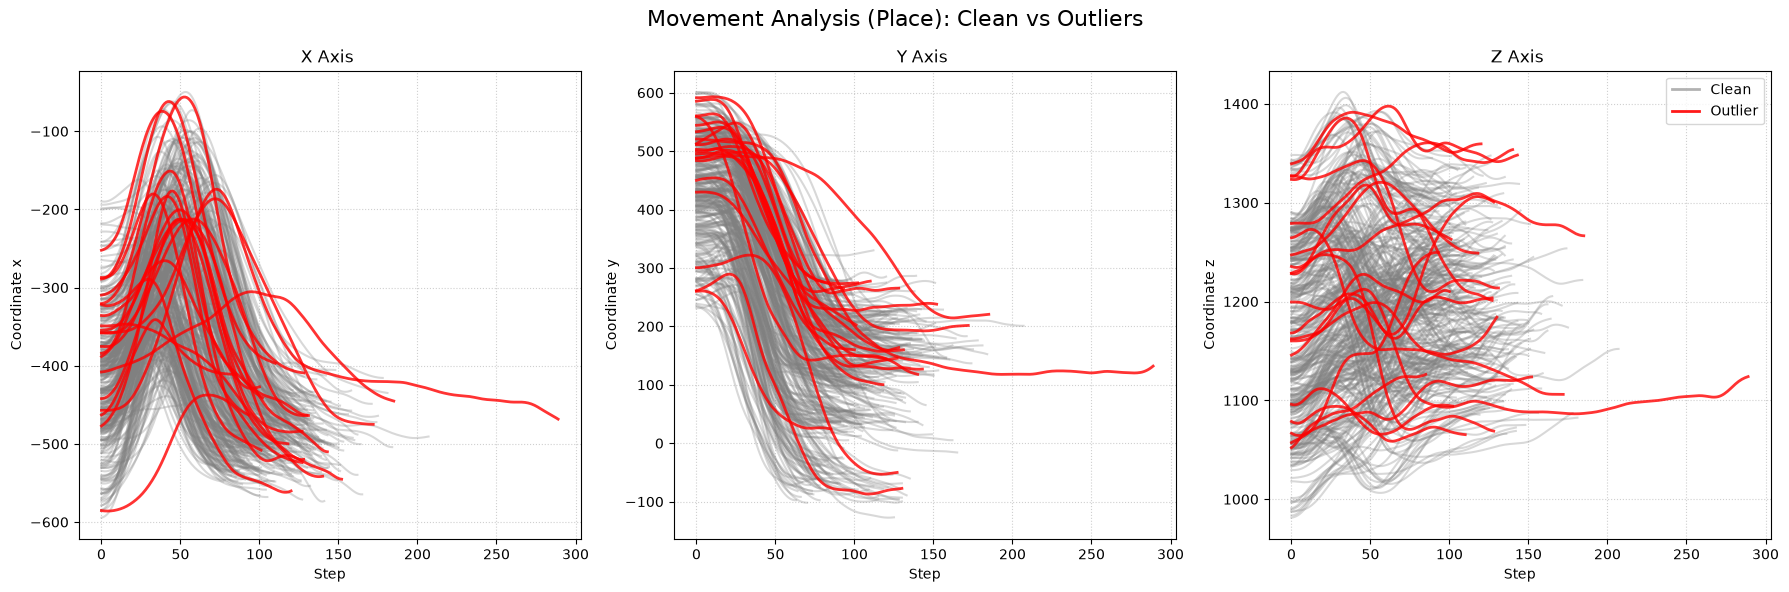

In [12]:
# 1. Ver as trajetórias do Ombro (Índices 0, 1, 2)
print("A desenhar trajetórias do Ombro...")
plot_movement_data(X_movement_clean[:, :, 0:3], X_movement_outliers[:, :, 0:3], TARGET_MOVEMENT)

# 2. Ver as trajetórias do Cotovelo (Índices 3, 4, 5)
print("A desenhar trajetórias do Cotovelo...")
plot_movement_data(X_movement_clean[:, :, 3:6], X_movement_outliers[:, :, 3:6], TARGET_MOVEMENT)

# 3. Ver as trajetórias do Pulso/Mão (Índices 6, 7, 8)
print("A desenhar trajetórias do Pulso...")
plot_movement_data(X_movement_clean[:, :, 6:9], X_movement_outliers[:, :, 6:9], TARGET_MOVEMENT)